<a href="https://colab.research.google.com/github/Shadid123/Digital-Image-Processing/blob/main/Assignment%203/3.3_Histogram_Equalization_CDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

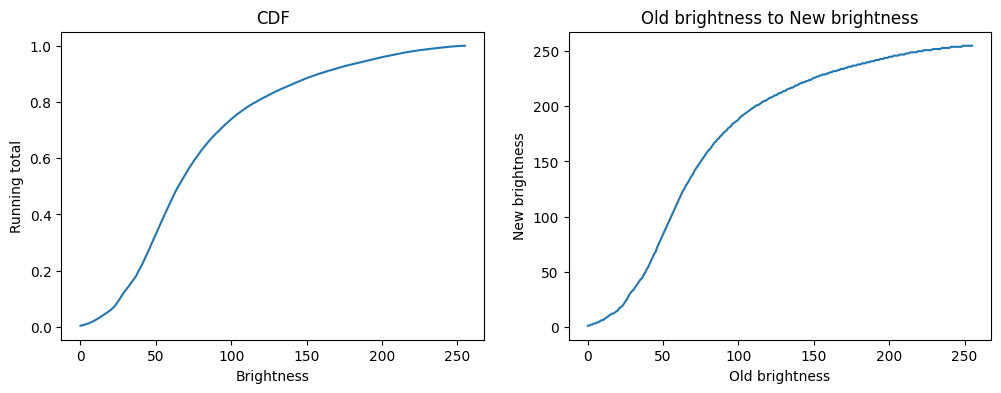

In [ ]:
import numpy as np                  # tool for working with numbers and lists
import cv2                          # tool for reading the image
import matplotlib.pyplot as plt     # tool for drawing graphs

img = cv2.imread("/content/input.jpg", cv2.IMREAD_GRAYSCALE)   # open the picture in black and white
L = 256                             # 256 brightness values (0 to 255)
M, N = img.shape                    # height and width of the picture

hist = np.zeros(L)                  # 256 empty boxes
for v in img.ravel():               # take every pixel one by one
    hist[v] += 1                    # count it in the box of its brightness
pdf = hist / (M * N)                # change counts into fractions

cdf = np.cumsum(pdf)                # running total of the fractions
                                    # example: [0.1, 0.2, 0.3] becomes [0.1, 0.3, 0.6]
                                    # it tells: what fraction of pixels are this dark or darker

new_value = np.round(255 * cdf)     # new brightness for each old brightness
                                    # this is the rule we use to improve the picture

plt.figure(figsize=(12, 4))         # make a wide drawing area for 2 graphs

plt.subplot(1, 2, 1)                # first graph (left side)
plt.plot(cdf)                       # draw the running total line
plt.title('CDF')                    # title of the first graph
plt.xlabel('Brightness')            # bottom line shows brightness
plt.ylabel('Running total')         # side line shows the running total (0 to 1)

plt.subplot(1, 2, 2)                # second graph (right side)
plt.plot(new_value)                 # draw old brightness vs new brightness
plt.title('Old brightness to New brightness')   # title of the second graph
plt.xlabel('Old brightness')        # bottom line shows old brightness
plt.ylabel('New brightness')        # side line shows new brightness

plt.show()                          # show both graphs